# Transformer from scratch
### 08/2026 | Wolf Gautier
#### Based largely on [Arena's Ch1.1](https://learn.arena.education/chapter1_transformer_interp/01_transformers/intro)
This notebook serves as an introduction into the transformer architecture as a whole. It consists of two sections; a **from-scratch implementation of transformer components and subsequently a transformer** and then **implementation of various sampling methods**. The goal is to develop an understanding of the architecture as context for later interpretability work using the **TransformerLens** library.

In [ ]:
!pip install --upgrade transformer_lens==4.0.0 circuitsvis==1.43.3

In [ ]:
import sys
from collections import defaultdict
from dataclasses import dataclass
from pathlib import Path
from typing import Callable

import datasets
import einops
import numpy as np
import torch as t
import torch.nn as nn
from rich import print as rprint
from rich.table import Table
from torch import Tensor
from tqdm.notebook import tqdm

import circuitsvis as cv

import transformer_lens
from transformer_lens.model_bridge import TransformerBridge
from transformer_lens.utilities import gelu_new, tokenize_and_concatenate
from transformers import GPT2TokenizerFast
from jaxtyping import Float, Int


## Transformers & transformer components
In essence, a transformer is a sequential machine learning model mostly used for text generation/prediction. It takes language as input, and outputs a probability distribution over its token dictionary, which can be sampled to generate text. It is **autoregressive**, meaning text is generated by feeding it its own output, i.e. a token sequence of length $N$ is fed as initial input, obtaining as output a predicted next token, which is appended after which the model is fed the now $N+1$-length sequence to obtain a sequence of length $N+2$, etc.

### Data format: Tokenization
The input and output of a transformer model are text, but this text is broken up into **tokens**. These are combinations of ASCII tokens, i.e.

```
"The sheep walks" -> "The", " sh", "eep", " wa", "lks"
```


> **Why not just work directly with ASCII characters**? This has been done, but it loses the structure inherent to language; "machine" carries more significance than "akgjdn3" and treating these "words" the same would be computationally inefficient. Additionally, the compute of the attention mechanism of a transformer scales with sequence length as $\sim O(n^2)$, meaning having a larger dictionary tends to be outweighed by additional computational costs of per-character processing, while still allows for processing of arbitrary text.

This allows the model to output confidence values for each of the tokens in its total token dictionary being the next token in the sequence.

### Text generation: End-to-end data pipeline
The process of obtaining a predicted text through autoregression concretely consists of 5 looping steps.
1. The input text is converted to tokens, which allows a text to be expressed as a tensor of shape ```[n_tokens, dict_size]```; if the first token in the dictionary is ```"Do"``` and the third is ```"g "```, "Dog" would be represented as the tensor ```[[1., 0., 0., 0., ...], [0., 0., 1., 0., ...]```.
2. This is fed through the transformer, for which the output becomes a probability distribution over its dictionary of shape, for example ```[.04, .001, .17, ...]```. In a Bayesian framing, this tensor expresses the confidence of the model that token $n$ is the next in the sequence. This allows training to take the form of token prediction, which is improved upon by minimising a cross entropy loss; for one token, this is computed as
$$ L = \sum_{i=1}^{C}(y_i \log(p_i)), $$
where $C$ is the number of classes, $y_i$ is 1 if the token at index $i$ in the dictionary is the true next token and 0 if not, and $p_i$ is the logit the model predicted.
3. From the computed logits, a token has to be selected. The one with the highest predicted logit is not always the right choice; language is complex, and considering things like sentence structure and repetition when turning the model's probability distribution into a next token turns out to be crucial for overall performance. The chosen token is appended to the current sequence, which is fed back to the model in its entirety, after which steps 1-3 are repeated.

###


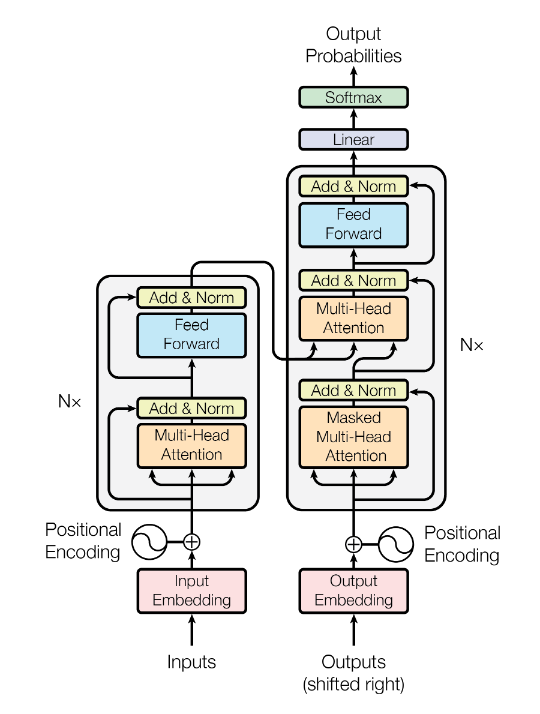



The transformer architecture as outlined in the paper that presented it; [*Attention is all you need*](https://proceedings.neurips.cc/paper_files/paper/2017/file/3f5ee243547dee91fbd053c1c4a845aa-Paper.pdf?src_trk=em66c5166b7bad47.12959706424423622)

### Non-attention internal components
The transformer model itself is made up of a group of different components, one of which is the core of its performance. The following code cell defines the following;

*   ```LayerNorm```: normalisation, used to have each input vector have mean=0 and variance=1
*   ```Embed```: an embedding (linear mapping) from ```d_dictionary``` to the dimensionality of the model
* ```PosEmbed```: transformers operate across all combinations of positions, which means there is no native positional awareness. This learned embedding is added (not concatenated) to the embedded vector, allowing the model to learn relative positioning
* ```Unembed```: an embedding (linear mapping) from the dimensionality of the model to ```d_dictionary```, used to go from the final internal state of the model to logits on the model's dictionary
* ```MLP``` (MultiLayer Perceptron): a regular neural network with one hidden layer and a nonlinear activation function



In [ ]:
# Find usable GPUs else use CPU
device = t.device("cuda" if t.cuda.is_available() else "cpu")

# Simplified config class
@dataclass
class Config:
    d_model: int = 768
    debug: bool = True
    layer_norm_eps: float = 1e-5
    d_vocab: int = 50257
    init_range: float = 0.02
    n_ctx: int = 1024
    d_head: int = 64
    d_mlp: int = 3072
    n_heads: int = 12
    n_layers: int = 12


class LayerNorm(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.w = nn.Parameter(t.ones(cfg.d_model))
        self.b = nn.Parameter(t.zeros(cfg.d_model))

    def forward(self, residual: Float[Tensor, "batch posn d_model"]) -> Float[Tensor, "batch posn d_model"]:
        return (
            (residual - residual.mean(dim=-1, keepdim=True)) /
            (residual.var(dim=-1, keepdim=True, unbiased=False) + self.cfg.layer_norm_eps).sqrt()
        ) * self.w + self.b


class Embed(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.W_E = nn.Parameter(t.empty((cfg.d_vocab, cfg.d_model)))
        nn.init.normal_(self.W_E, std=self.cfg.init_range)

    def forward(self, tokens: Int[Tensor, "batch position"]) -> Float[Tensor, "batch position d_model"]:
        return self.W_E[tokens]


class PosEmbed(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.W_pos = nn.Parameter(t.empty((cfg.n_ctx, cfg.d_model)))
        nn.init.normal_(self.W_pos, std=self.cfg.init_range)

    def forward(self, tokens: Int[Tensor, "batch position"]) -> Float[Tensor, "batch position d_model"]:
        bs, seq_len = tokens.shape
        return self.W_pos[:seq_len].repeat(bs, 1, 1)


class Unembed(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.W_U = nn.Parameter(t.empty((cfg.d_model, cfg.d_vocab)))
        nn.init.normal_(self.W_U, std=self.cfg.init_range)
        self.b_U = nn.Parameter(t.zeros((cfg.d_vocab)), requires_grad=False)

    def forward(
        self, normalized_resid_final: Float[Tensor, "batch position d_model"]
    ) -> Float[Tensor, "batch position d_vocab"]:
        return einops.einsum(
            normalized_resid_final,
            self.W_U,
            "batch position d_model, d_model d_vocab -> batch position d_vocab"
        ) + self.b_U


class MLP(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.W_in = nn.Parameter(t.empty((cfg.d_model, cfg.d_mlp)))
        self.W_out = nn.Parameter(t.empty((cfg.d_mlp, cfg.d_model)))
        self.b_in = nn.Parameter(t.zeros((cfg.d_mlp)))
        self.b_out = nn.Parameter(t.zeros((cfg.d_model)))
        nn.init.normal_(self.W_in, std=self.cfg.init_range)
        nn.init.normal_(self.W_out, std=self.cfg.init_range)

    def forward(self, normalized_resid_mid: Float[Tensor, "batch posn d_model"]) -> Float[Tensor, "batch posn d_model"]:
        # Linear layer
        projection = gelu_new(
            einops.einsum(
                normalized_resid_mid,
                self.W_in,
                "batch posn d_model, d_model d_mlp -> batch posn d_mlp"
            ) + self.b_in
        )

        # Output projection
        output = einops.einsum(
            projection,
            self.W_out,
            "batch posn d_mlp, d_mlp d_model -> batch posn d_model"
        ) + self.b_out

        return output


### Attention
The attention component of a transformer, written in the following code cell, essentially moves information from prior sequence positions to a current token through a distribution called an attention pattern; *how much attention should be paid to each token?*
> To better understand this conceptually, going back to language can help gain intuition; to properly understand the sentence **"A small red dog runs after a large ball"**, there are a lot of inter-word relations that we naturally take into account. The words "small" and "red" are highly relevant to the word "dog", while only "small" is potentially relevant to the word "ball", but only because "ball" is described as "large" while being relevant to "dog" because of the word "after". Mapping the relevance of each inter-word relation is what the attention component does; it essentially learns and predicts how relevant one token is to another, and overall.

Each attention head, of which a model has multiple that each develop their own attention pattern, consists of three components; keys $K$, queries $Q$ and values $V$. Roughly, **queries** are information requests ("I am looking for a name earlier in a sentence"), **keys** represent whether that information can be found at a given token, and **values** represent the actual value (keys and values are not the same; in the case of the name query, a key might be a signal that a name is present, and the corresponding value then contains the name itself). These interplay to make an attention model as:

$$ Attention(Q,K,V) = softmax\left(\frac{QK^\top}{\sqrt{d_k}}\right)V, $$

essentially meaning "compare every query against every key, scale, softmax and multiply by values".

In [ ]:
class Attention(nn.Module):
    IGNORE: Float[Tensor, ""]

    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.W_Q = nn.Parameter(t.empty((cfg.n_heads, cfg.d_model, cfg.d_head)))
        self.W_K = nn.Parameter(t.empty((cfg.n_heads, cfg.d_model, cfg.d_head)))
        self.W_V = nn.Parameter(t.empty((cfg.n_heads, cfg.d_model, cfg.d_head)))
        self.W_O = nn.Parameter(t.empty((cfg.n_heads, cfg.d_head, cfg.d_model)))
        self.b_Q = nn.Parameter(t.zeros((cfg.n_heads, cfg.d_head)))
        self.b_K = nn.Parameter(t.zeros((cfg.n_heads, cfg.d_head)))
        self.b_V = nn.Parameter(t.zeros((cfg.n_heads, cfg.d_head)))
        self.b_O = nn.Parameter(t.zeros((cfg.d_model)))
        nn.init.normal_(self.W_Q, std=self.cfg.init_range)
        nn.init.normal_(self.W_K, std=self.cfg.init_range)
        nn.init.normal_(self.W_V, std=self.cfg.init_range)
        nn.init.normal_(self.W_O, std=self.cfg.init_range)
        self.register_buffer("IGNORE", t.tensor(float("-inf"), dtype=t.float32, device=device))

    def forward(self, normalized_resid_pre: Float[Tensor, "batch posn d_model"]) -> Float[Tensor, "batch posn d_model"]:
        # Compute projections
        Q = einops.einsum(
            normalized_resid_pre,
            self.W_Q,
            "batch posn d_model, n_heads d_model d_head -> batch posn n_heads d_head"
        ) + self.b_Q
        K = einops.einsum(
            normalized_resid_pre,
            self.W_K,
            "batch posn d_model, n_heads d_model d_head -> batch posn n_heads d_head"
        ) + self.b_K
        V = einops.einsum(
            normalized_resid_pre,
            self.W_V,
            "batch posn d_model, n_heads d_model d_head -> batch posn n_heads d_head"
        ) + self.b_V

        # Compute, scale and mask attention values and obtain probabilities through softmax
        attn_probs = self.apply_causal_mask(
            einops.einsum(
                Q,
                K,
                "batch posn_Q n_heads d_head, batch posn_K n_heads d_head -> batch n_heads posn_Q posn_K"
            ) / self.cfg.d_head**.5
        ).softmax(dim=-1)

        # Apply to V to "obtain pointed to information"
        v_sum = einops.einsum(
            V,
            attn_probs,
            "batch posn_K n_heads d_head, batch n_heads posn_Q posn_K -> batch posn_Q n_heads d_head"
        )

        # Apply output matrix + bias and sum over head to obtain output
        return einops.einsum(
            v_sum,
            self.W_O,
            "batch posn_Q n_heads d_head, n_heads d_head d_model -> batch posn_Q d_model"
        ) + self.b_O

    def apply_causal_mask(
        self, attn_scores: Float[Tensor, "batch n_heads query_pos key_pos"]
    ) -> Float[Tensor, "batch n_heads query_pos key_pos"]:
        """
        Applies a causal mask to attention scores, and returns masked scores.
        """
        mask = t.triu(
            t.ones_like(attn_scores),
            diagonal=1
        ).bool()
        return attn_scores.masked_fill_(mask, self.IGNORE)


To better understand what an attention mechanism looks like and does in practice, we can visualise the attention patterns of each head of a pretrained transformer model. This allows us to see directly what "attention" each head gives to each token, for each token.

In [ ]:
# Load a trained instance of GPT2 from HF
trained_gpt2 = TransformerBridge.boot_transformers("gpt2")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [ ]:
from IPython.display import display

reference_text = "A small red dog runs after a large ball and falls over"

# Tokenize
tokens = trained_gpt2.to_tokens(reference_text).to(device)[:, 1:]

# Feed to model to obtain logits
logits, cache = trained_gpt2.run_with_cache(tokens)

display(
    cv.attention.attention_patterns(
        tokens=trained_gpt2.to_str_tokens(reference_text)[1:], attention=cache["pattern", 0][0]
    )
)

Having built all of the transformer components, we can combine them into a transformer block, and combine blocks into a transformer model;

In [ ]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.ln1 = LayerNorm(cfg)
        self.attn = Attention(cfg)
        self.ln2 = LayerNorm(cfg)
        self.mlp = MLP(cfg)

    def forward(self, resid_pre: Float[Tensor, "batch position d_model"]) -> Float[Tensor, "batch position d_model"]:
        resid_post_attn = self.attn(self.ln1(resid_pre)) + resid_pre
        return self.mlp(self.ln2(resid_post_attn)) + resid_post_attn


class Transformer(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.embed = Embed(cfg)
        self.pos_embed = PosEmbed(cfg)
        self.blocks = nn.ModuleList([TransformerBlock(cfg) for _ in range(cfg.n_layers)])
        self.ln_final = LayerNorm(cfg)
        self.unembed = Unembed(cfg)

    def forward(self, tokens: Int[Tensor, "batch position"]) -> Float[Tensor, "batch position d_vocab"]:
        x = self.embed(tokens) + self.pos_embed(tokens)
        for block in self.blocks:
            x = block(x)
        logits = self.unembed(self.ln_final(x))
        return logits


## Demo: sample with pretrained GPT2 weights
Normally, we would now train the built transformer model on a large text dataset, but for demonstration purposes we can just load pre-trained weights and load those into our model.

In [ ]:
# Load the raw state dict of the model loaded earlier directly onto an instance of the transformer architecture we constructed
demo_gpt2 = Transformer(Config(debug=False)).to(device)
demo_gpt2.load_state_dict(trained_gpt2.get_params(), strict=False)

_IncompatibleKeys(missing_keys=['blocks.0.attn.IGNORE', 'blocks.1.attn.IGNORE', 'blocks.2.attn.IGNORE', 'blocks.3.attn.IGNORE', 'blocks.4.attn.IGNORE', 'blocks.5.attn.IGNORE', 'blocks.6.attn.IGNORE', 'blocks.7.attn.IGNORE', 'blocks.8.attn.IGNORE', 'blocks.9.attn.IGNORE', 'blocks.10.attn.IGNORE', 'blocks.11.attn.IGNORE'], unexpected_keys=[])

We can now have the model predict tokens! Here we implement the 3-step text generation pipeline described earlier; we let the model autoregressively predict the next 40 tokens, based on on initial input text.

In [ ]:
test_string = """Machine learning is""" # Change this to experiment

print(test_string, end="")

# Loop over 40 tokens
for i in tqdm(range(40)):

    # Tokenise the current string
    test_tokens = trained_gpt2.to_tokens(test_string).to(device)

    # Obtain logits with our own model
    demo_logits = demo_gpt2(test_tokens)

    # Decode the token with the highest confidence
    next_token = trained_gpt2.tokenizer.decode(demo_logits[-1, -1].argmax())

    # Append the decoded token to the string
    test_string += next_token

    print(next_token, end="")


Machine learning is

  0%|          | 0/40 [00:00<?, ?it/s]

 a new field of research that has been gaining momentum in recent years. It is a field that has been gaining traction in the last few years, but it is still very much a work in progress.

## Sampling
Having built a transformer and obtained some output, we can now look at different ways of selecting a next token based on the model output logits (**sampling**). We cover the following methods and tools;
* **Basic sampling**: use the found logits to create a distribution and sample (randomly) from that
* **Temperature adjustment**: make the final distribution "sharper", so lowers low probabilities and heightens high probabilities
* **Apply a frequency penalty**: compute and apply a penalty for tokens that are recurringly present with an overly high probability
* **top-k sampling**: sample from the top $k$ logits only
* **top-p sampling**: sample from the top $n$ logits that have a combined probability of $p$

In [ ]:
class TransformerSampler:
    def __init__(self, model: Transformer, tokenizer: GPT2TokenizerFast):
        self.model = model
        self.cfg = model.cfg
        self.tokenizer = tokenizer

    @t.inference_mode()
    def sample(self, prompt: str, max_tokens_generated=100, verbose=False, **kwargs) -> str:
        """
        Returns a string of autoregressively generated text, starting from the prompt.

        Sampling terminates at max_tokens_generated, or when the model generates an end-of-sequence token. kwargs are
        passed to sample_next_token, to give detailed instructions on how new tokens are chosen.
        Pass `seed` to make generation reproducible.
        """
        self.model.eval()
        seed = kwargs.pop("seed", None)
        if seed is not None:
            t.manual_seed(seed)
            np.random.seed(seed)

        ids = self.tokenizer.encode(prompt, return_tensors="pt").to(device)[0, 1:]

        for i in range(max_tokens_generated):
            logits = self.model(
                ids[None, -self.cfg.n_ctx:] # Cut off from the front according to context length setting
            )[0,-1]

            next_id = self.sample_next_token(ids, logits)
            ids = t.cat([ids, t.Tensor([next_id]).int()])

            if verbose:
                if i == 0:
                    print(self.tokenizer.decode(ids), end="")
                else:
                    print(self.tokenizer.decode(ids[-1]), end="")
            if next_id == getattr(self.tokenizer, "eos_token_id", None):
                break

        return self.tokenizer.decode(ids)

    @staticmethod
    def sample_next_token(
        input_ids: Int[Tensor, " seq_len"],
        logits: Float[Tensor, "d_vocab"],
        temperature=1.0,
        top_k=0,
        top_p=0.0,
        frequency_penalty=0.0,
    ) -> int:
        assert input_ids.ndim == 1, "input_ids should be a 1D sequence of token ids"
        assert logits.ndim == 1, "logits should be a 1D tensor of shape (d_vocab,)"
        assert temperature >= 0, "Temperature should be non-negative"
        assert 0 <= top_p <= 1.0, "Top-p must be a probability"
        assert 0 <= top_k, "Top-k must be non-negative"
        assert not (top_p != 0 and top_k != 0), "At most one of top-p and top-k supported"

        # Apply all the specialized sampling methods
        if temperature != 1.0:
            logits = TransformerSampler.apply_temperature(logits, temperature)
        if frequency_penalty != 0.0:
            logits = TransformerSampler.apply_frequency_penalty(input_ids, logits, frequency_penalty)
        if top_k > 0:
            return TransformerSampler.sample_top_k(logits, top_k)
        if top_p > 0.0:
            return TransformerSampler.sample_top_p(logits, top_p)
        return TransformerSampler.sample_basic(logits)

    @staticmethod
    def apply_temperature(logits: Float[Tensor, "d_vocab"], temperature: float) -> Float[Tensor, "d_vocab"]:
        """
        Applies temperature scaling to the logits.
        """
        return logits / temperature

    @staticmethod
    def apply_frequency_penalty(
        input_ids: Int[Tensor, " seq_len"], logits: Float[Tensor, "d_vocab"], freq_penalty: float
    ) -> Float[Tensor, "d_vocab"]:
        """
        Applies a frequency penalty to the logits.
        """
        d_vocab = logits.size(0)
        id_freqs = t.bincount(input_ids, minlength=d_vocab)
        return logits - freq_penalty * id_freqs

    @staticmethod
    def sample_basic(logits: Float[Tensor, "d_vocab"]) -> int:
        """
        Samples from the distribution defined by the logits.
        """
        return t.distributions.categorical.Categorical(logits=logits).sample().item()

    @staticmethod
    def sample_top_k(logits: Float[Tensor, "d_vocab"], k: int) -> int:
        """
        Samples from the top k most likely tokens.
        """
        top_k_logits, top_k_token_ids = logits.topk(k)
        sampled_token_idx = t.distributions.categorical.Categorical(logits=top_k_logits).sample()
        return top_k_token_ids[sampled_token_idx].item()

    @staticmethod
    def sample_top_p(logits: Float[Tensor, "d_vocab"], top_p: float, min_tokens_to_keep: int = 1) -> int:
        """
        Samples from the most likely tokens which make up at least p cumulative probability.
        """
        probs = logits.softmax(dim=-1)
        sorted_probs, sorted_idx = t.sort(probs, descending=True)

        # Remove tokens after the first token that brings cumulative probability
        # to or above top_p
        cumulative = sorted_probs.cumsum(dim=-1)
        remove = cumulative > top_p

        # Always keep the token that crosses the top-p boundary
        remove[1:] &= cumulative[:-1] >= top_p

        # And enforce the minimum number of tokens
        remove[:min_tokens_to_keep] = False

        # Renormalize over the retained distribution and sample
        probs = sorted_probs.masked_fill(remove, 0.0)
        probs /= probs.sum()

        sampled = t.multinomial(probs, num_samples=1)

        return sorted_idx[sampled].item()


First, let's try a basic (categorical) sample (this cell is non-seeded, so rerun it a few times to see different outputs. Note that while the model itself is deterministic, the sampling allows for different outputs each times):

In [ ]:
prompt = "Hi! My name is"

tokenizer = trained_gpt2.tokenizer
sampler = TransformerSampler(demo_gpt2, tokenizer)

output = sampler.sample(prompt, max_tokens_generated=40, verbose=True)


Hi! My name is Alex. Well, you're my computer DAVE (You know what I mean) but maybe not. Just the way you do Join TotalPlease.

DCBOOM: What are you doing

Now let's perform some comparative sampling runs with different settings and compare outputs:

In [ ]:
N_RUNS = 1
prompt = "Machine learning is" # "Jingle bells, jingle bells, jingle all the way"
cases = [
    ("High freq penalty", dict(frequency_penalty=100.0)),
    ("Negative freq penalty", dict(frequency_penalty=-3.0)),
    ("Too high T", dict(temperature=2.0)),
    ("T=.7", dict(temperature=0.7)),
    ("T=.9", dict(temperature=0.9)),
    ("Too low T", dict(temperature=0.01)),
    ("Top-k (40)", dict(top_k=40)),
    ("Top-p (95%)", dict(top_p=0.95)),
]

table = Table("Name", "Kwargs", "Output", title="Sampling results")

for name, kwargs in cases:
    for i in range(N_RUNS):
        output = sampler.sample(prompt, max_tokens_generated=24, **kwargs)
        table.add_row(name, str(kwargs), repr(output) + "\n")

rprint(table)

                                                 Sampling results                                                  
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Name                  ┃ Kwargs                       ┃ Output                                                   ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ High freq penalty     │ {'frequency_penalty': 100.0} │ 'Machine learning is an expression of neural             │
│                       │                              │ recognition, and education for children is deeply infuse │
│                       │                              │ with it: Wales uses more education for learning          │
│                       │                              │ literacy'                                                │
│                       │                              │                                                          │
│ Negative freq penalty │ {'frequency_penalty': -3.0}  │ 'Machine learning is just being developed now on Airtel  │
│                       │                              │ an CEO and other leading security companies spy on your  │
│                       │                              │ web traffic and may breach your'                         │
│                       │                              │                                                          │
│ Too high T            │ {'temperature': 2.0}         │ 'Machine learning is born of experience with a long      │
│                       │                              │ pipeline of innovations rather than an abstract concept  │
│                       │                              │ of sampling. Its broad range and diversity now includes' │
│                       │                              │                                                          │
│ T=.7                  │ {'temperature': 0.7}         │ 'Machine learning is here to stay, as it allows you to   │
│                       │                              │ synthesize whole games and adapt to different            │
│                       │                              │ environments. Ganon: Battle Over'                        │
│                       │                              │                                                          │
│ T=.9                  │ {'temperature': 0.9}         │ 'Machine learning is an emerging field with lower        │
│                       │                              │ volumetric attenuation. Interpretation of functional     │
│                       │                              │ patterns using the downstream modifications (stabilities │
│                       │                              │ for'                                                     │
│                       │                              │                                                          │
│ Too low T             │ {'temperature': 0.01}        │ 'Machine learning is necessary to create relevant,       │
│                       │                              │ consistent online enterprise instructions for our teams. │
│                       │                              │ As we take the next tremendous step in developing        │
│                       │                              │ algorithmic'                                             │
│                       │                              │                                                          │
│ Top-k (40)            │ {'top_k': 40}                │ "Machine learning is very, very effective. We've tended  │
│                       │                              │ to edge toward reasoning power where our intuition       │
│                       │                              │ points to one thing or another, and"                     │
│                       │                              │